In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import torch
import torchinfo
from torch.utils.data import DataLoader
from torchlake.common.constants import IMAGENET_MEAN, IMAGENET_STD
from torchlake.common.controller.trainer import ClassificationTrainer
from torchlake.common.controller.evaluator import ClassificationEvaluator
from torchlake.common.utils.platform import get_num_workers, get_file_size
from torchlake.image_classification.models.mobileone import MobileOne
from torchvision import transforms
from torchvision.datasets import GTSRB

# Setting

In [2]:
IMAGE_SIZE = 224
BATCH_SIZE = 64

In [3]:
artifact_path = Path("../../artifacts/mobileone")
artifact_path.mkdir(exist_ok=True)

data_path = Path("../../data/gtsrb")

In [4]:
DEVICE = torch.device("cuda:0")

# data

In [5]:
preprocess = transforms.Compose(
    [
        transforms.ColorJitter(brightness=0.2, saturation=0.2, contrast=0.2),
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ]
)

In [6]:
train_dataset = GTSRB(
    data_path.as_posix(),
    split="train",
    transform=preprocess,
    download=True,
)

In [7]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=True,
    pin_memory=True,
    num_workers=get_num_workers(),
)

In [8]:
num_class = 43

In [9]:
len(train_dataset)

26640

10


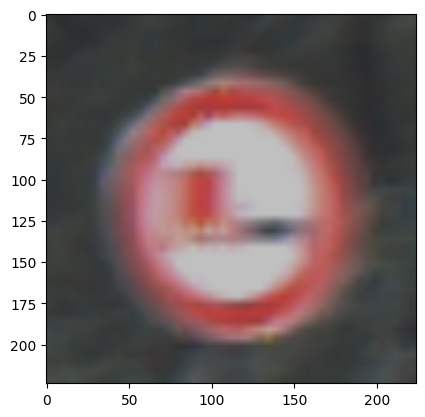

In [10]:
import random
from torchlake.common.utils.convert import img_tensor_to_np

demo_img, demo_label = random.choice(train_dataset)
print(demo_label)
plt.imshow((img_tensor_to_np(demo_img) * IMAGENET_STD + IMAGENET_MEAN).clip(0, 1))

# model

In [11]:
model = MobileOne(output_size=num_class, key="s0").to(DEVICE)

In [12]:
torchinfo.summary(model)

Layer (type:depth-idx)                                            Param #
MobileOne                                                         --
├─RepVGGBlock: 1-1                                                --
│    └─Sequential: 2-1                                            --
│    │    └─InceptionModule: 3-1                                  1,632
│    │    └─ReLU: 3-2                                             --
├─Sequential: 1-2                                                 --
│    └─Sequential: 2-2                                            --
│    │    └─RepVGGBlock: 3-3                                      2,256
│    │    └─RepVGGBlock: 3-4                                      9,696
│    │    └─RepVGGBlock: 3-5                                      2,352
│    │    └─RepVGGBlock: 3-6                                      9,696
│    └─Sequential: 2-3                                            --
│    │    └─RepVGGBlock: 3-7                                      2,256
│    │    └

# training

In [13]:
epochs = 10
acc_iters = 64 // BATCH_SIZE

In [14]:
trainer = ClassificationTrainer(epochs, DEVICE, acc_iters)
trainer.recorder.increment_dataset_size(len(train_dataset))

In [15]:
criterion = trainer.get_criterion(num_class)
optim = torch.optim.Adam(model.parameters())

In [16]:
training_loss = trainer.run(train_loader, model, optim, criterion)

Enable AMP: False
Training...


100%|██████████| 416/416 [14:36<00:00,  2.11s/it]


------------------------------------
Epoch 1
------------------------------------
total: 4.3749e-02 (0.00%)


100%|██████████| 416/416 [02:40<00:00,  2.60it/s]


------------------------------------
Epoch 2
------------------------------------
total: 1.8531e-02 (-58.00%)


100%|██████████| 416/416 [02:40<00:00,  2.59it/s]


... (11 outputs left out)

100%|██████████| 416/416 [02:27<00:00,  2.83it/s]


------------------------------------
Epoch 9
------------------------------------
total: 5.8975e-04 (4.00%)


100%|██████████| 416/416 [02:38<00:00,  2.63it/s]

------------------------------------
Epoch 10
------------------------------------
total: 5.1189e-04 (-13.00%)


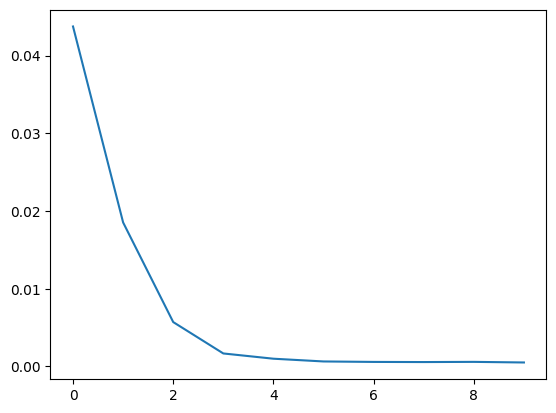

In [17]:
plt.plot(training_loss)

# inference

In [18]:
test_preprocess = transforms.Compose(
    [
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ]
)

In [19]:
test_dataset = GTSRB(
    data_path.as_posix(),
    split="test",
    transform=test_preprocess,
    download=True,
)

In [20]:
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    pin_memory=True,
    num_workers=get_num_workers(),
)

In [31]:
evaluator = ClassificationEvaluator(num_class, DEVICE)

In [32]:
confusion_matrix = evaluator.run(test_loader, model)

100%|██████████| 198/198 [00:34<00:00,  5.73it/s]


In [33]:
per_class_acc = evaluator.get_per_class_accuracy(confusion_matrix)
evaluator.show_per_class_accuracy(range(num_class), per_class_acc)

0         : 1.0
1         : 0.9930555555555556
2         : 0.9626666666666667
3         : 0.9555555555555556
4         : 0.9848484848484849
5         : 0.9873015873015873
6         : 0.7933333333333333
7         : 0.94
8         : 0.8911111111111111
9         : 0.9958333333333333
10        : 0.9803030303030303
11        : 0.9976190476190476
12        : 0.9130434782608695
13        : 0.9958333333333333
14        : 0.9814814814814815
15        : 0.9523809523809523
16        : 1.0
17        : 0.8916666666666667
18        : 0.8794871794871795
19        : 0.8333333333333334
20        : 1.0
21        : 0.5666666666666667
22        : 0.75
23        : 0.94
24        : 0.9
25        : 0.9770833333333333
26        : 0.9388888888888889
27        : 0.55
28        : 1.0
29        : 0.8222222222222222
30        : 0.32
31        : 0.9518518518518518
32        : 0.9833333333333333
33        : 0.9952380952380953
34        : 1.0
35        : 0.958974358974359
36        : 0.975
37        : 0.9333333333333

In [34]:
per_class_acc.mean()

np.float64(0.8985427891679156)

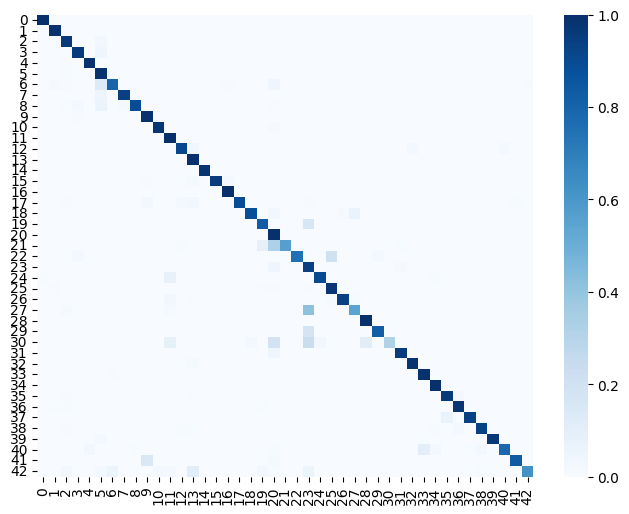

In [35]:
evaluator.plot_confusion_matrix(
    confusion_matrix,
    range(num_class),
    "Blues",
    annot=False,
    figsize=(8, 6),
)

In [26]:
model_path = artifact_path / f"mobileone.{model.key}.pth"

In [27]:
torch.save(model.state_dict(), model_path)

In [28]:
get_file_size(model_path)

'17.25MiB'

In [29]:
model.load_state_dict(torch.load(model_path.as_posix()))

<All keys matched successfully>

## reparametrize

In [39]:
reparametrized_model = model.reparameterize()

In [49]:
evaluator = ClassificationEvaluator(num_class, DEVICE)

In [50]:
confusion_matrix = evaluator.run(test_loader, reparametrized_model)

100%|██████████| 198/198 [00:24<00:00,  7.95it/s]


In [51]:
per_class_acc = evaluator.get_per_class_accuracy(confusion_matrix)
evaluator.show_per_class_accuracy(range(num_class), per_class_acc)

0         : 1.0
1         : 0.9930555555555556
2         : 0.9626666666666667
3         : 0.9555555555555556
4         : 0.9848484848484849
5         : 0.9873015873015873
6         : 0.7933333333333333
7         : 0.94
8         : 0.8911111111111111
9         : 0.9958333333333333
10        : 0.9803030303030303
11        : 0.9976190476190476
12        : 0.9130434782608695
13        : 0.9958333333333333
14        : 0.9814814814814815
15        : 0.9523809523809523
16        : 1.0
17        : 0.8916666666666667
18        : 0.8794871794871795
19        : 0.8333333333333334
20        : 1.0
21        : 0.5666666666666667
22        : 0.75
23        : 0.94
24        : 0.9
25        : 0.9770833333333333
26        : 0.9388888888888889
27        : 0.55
28        : 1.0
29        : 0.8222222222222222
30        : 0.32
31        : 0.9518518518518518
32        : 0.9833333333333333
33        : 0.9952380952380953
34        : 1.0
35        : 0.958974358974359
36        : 0.975
37        : 0.9333333333333

In [52]:
per_class_acc.mean()

np.float64(0.8985427891679156)

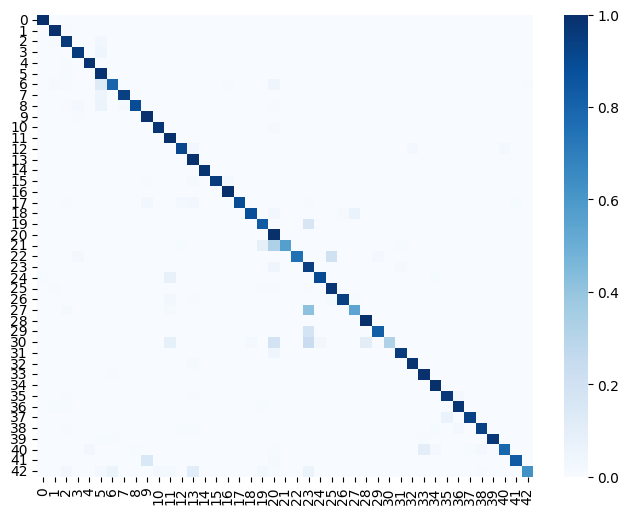

In [53]:
evaluator.plot_confusion_matrix(
    confusion_matrix,
    range(num_class),
    "Blues",
    annot=False,
    figsize=(8, 6),
)

In [54]:
model_path = artifact_path / f"mobileone.{model.key}.reparametrized.pth"

In [55]:
torch.save(reparametrized_model.state_dict(), model_path)

In [56]:
get_file_size(model_path)

'4.22MiB'

In [57]:
reparametrized_model.load_state_dict(torch.load(model_path.as_posix()))

<All keys matched successfully>